# 2. From labelled cells to an exported model

Notebook 1 ends with 81 model inputs. This notebook shows where the training cells come from, and
how `just train` and `just export` turn them into `cell-classifier.tflite`.

```mermaid
flowchart TD
    app["Labelling app<br>(just label-cells)"] --> tables["cells.csv, sudoku-photos.csv<br>(in git)"]
    app --> store["Image store<br>(not in git, SUD-08)"]
    tables --> read["read_real_cells"]
    store --> read
    read --> trust["training_cells<br>only trusted labels"]
    trust --> group["group_ids<br>near-duplicates and pages"]
    group --> split["split_by_group<br>a side from a hash"]
    fonts["ml/fonts/"] --> synth["synthetic.generate"]
    split --> batch["Batches: half synthetic,<br>half real"]
    synth --> batch
    batch --> aug["augment"] --> pre["preprocess_batch"] --> model["CellClassifier"]
    model --> temp["fit_temperature<br>on val"]
    temp --> metrics["metrics.json, model-card.md"]
    metrics --> export["just export<br>TFLite + checks"]
    export --> install["just install-model<br>into the app"]
```

| Part | Module | Command |
| --- | --- | --- |
| The tables and the trust rules | `tables.py`, `dataset.py` | `just check-data` |
| Synthetic cells | `synthetic.py` | (inside `just train`) |
| Augmentation | `augment.py` | (inside `just train`) |
| Groups and split | `dataset.py` | (inside `just train`) |
| Model and loss | `model.py`, `train.py` | `just train` |
| Calibration and metrics | `train.py` | `just train` |
| Export and checks | `export.py` | `just export <run>` |

The notebook trains a **small model on synthetic cells only**, in about two minutes. It uses the same
functions as `just train`. The real run of `configs/cell-classifier.toml` is far bigger.

## Setup

`SHOW_REAL_CELLS = False` keeps every real image out of the outputs. `SHOW_LOCAL_RUN = False`
keeps the metrics of your private runs out of them too (ADR-013). Then you can commit the
notebook with its outputs.

**Clear the outputs before you commit with `SHOW_REAL_CELLS = True`.** Real cell images must not
go into git (SUD-08). The counts of the tables are not images. `ml/dataset/STATUS.md` commits
them already.

In [1]:
import json
import tempfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from sudoku_ml import dataset, synthetic, train
from sudoku_ml.augment import augment
from sudoku_ml.contract import (
    DIGIT_CLASSES,
    KIND_CLASSES,
    UNKNOWN_KIND,
    kind_index,
)
from sudoku_ml.data_paths import ARTIFACTS, ML_ROOT, REPO_ROOT, DataPaths
from sudoku_ml.export import export
from sudoku_ml.model import CellClassifier
from sudoku_ml.preprocess import preprocess_batch
from sudoku_ml.tables import LABEL_SOURCES, TRUSTED_LABEL_SOURCES, read_cells, read_photos

plt.rcParams["figure.dpi"] = 90
plt.rcParams["image.cmap"] = "gray"
SHOW_REAL_CELLS = False
SHOW_LOCAL_RUN = False
data = DataPaths.under()
fonts = synthetic.font_files(ML_ROOT / "fonts")
print(len(fonts), "fonts")


def gallery(images, titles=None, columns=10, size=1.1):
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(columns * size, rows * size * 1.15))
    for i, ax in enumerate(np.atleast_1d(axes).flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i], vmin=0, vmax=255 if images[i].dtype == np.uint8 else 1)
            if titles:
                ax.set_title(titles[i], fontsize=7)
    plt.show()

7 fonts


## 1. The dataset

The real dataset has two parts (ADR-018):

- **Two tables in git.** `cells.csv` has one row per cell image. `sudoku-photos.csv` has one row
  per sudoku photo. Git keeps every version, so each training run names the exact data: the
  model card holds the hash of `cells.csv`.
- **The image store, outside git.** `ml/dataset/images/`, or the folder that `SUDOKU_IMAGES`
  names. The digit of a cell is the name of its folder: `cells/7/` holds the sevens.

The id of each image is the SHA-256 of its size and its RGB pixels. The same pixels always get
the same id, so the store holds each image once.

| Column of `cells.csv` | Meaning |
| --- | --- |
| `digit` | `empty` or `1` to `9`. Must match the folder |
| `kind` | `printed`, `handwritten` or `unsure`. Training ignores `unsure` |
| `photo_id`, `row`, `col` | The sudoku photo and the position the cell came from, if known |
| `label_source` | Who gave the label: empty (legacy), `verified`, `app-edited`, `app-unedited` |

In [2]:
if not data.cells_csv.exists():
    print("No cells.csv: this checkout has no dataset.")
else:
    rows = list(read_cells(data.cells_csv).values())
    photos = read_photos(data.photos_csv)
    print(f"{len(rows)} cells, {len(photos)} sudoku photos")
    table = Counter((r.digit, r.kind or "-") for r in rows)
    kinds = ["printed", "handwritten", "unsure", "-"]
    print(f"\n{'digit':>6} " + " ".join(f"{k:>12}" for k in kinds))
    for d in DIGIT_CLASSES:
        print(f"{d:>6} " + " ".join(f"{table[(d, k)]:>12}" for k in kinds))
    print("\nlabel_source:", dict(Counter(r.label_source or "(legacy)" for r in rows)))
    print("photo status:", dict(Counter(p.status for p in photos)))
    print("photo source:", dict(Counter(p.source for p in photos)))

33618 cells, 641 sudoku photos

 digit      printed  handwritten       unsure            -
 empty            0            0            0         9801
     1         1813          806            5            0
     2         1809          932            2            0
     3         1824          841            7            0
     4         1760          862            3            0
     5         1790          838            7            0
     6         1807          844            7            0
     7         1809          821            3            0
     8         1814          778            5            0
     9         1785          791            6            0

label_source: {'(legacy)': 33618}
photo status: {'legacy': 253, 'accepted': 215, 'rejected': 173}
photo source: {'phone': 219, 'web': 49, 'commons': 8, 'lexski': 170, 'openverse': 63, 'wicht': 132}


## 2. Which cells may train the model

A wrong label teaches the model the wrong answer. So `read_real_cells` and `training_cells` apply
two rules (ADR-030):

1. **The label must be trusted.** `TRUSTED_LABEL_SOURCES` holds the empty value (legacy cells, which
   a person labelled) and `verified`. A cell from an app scan is `app-edited` or `app-unedited`:
   the player's correction screen gave the label, and no person in the labelling app checked
   it yet.
2. **The outline must be accepted.** A wrong outline of a scan cuts every one of its 81 cells
   wrong. A cell of a scan whose outline is not `accepted` is left out, unless a person verified
   the cell itself.

An empty cell always gets the kind `none`. A digit cell with the kind `unsure`, or with no kind,
gets `UNKNOWN_KIND` = -1. It still trains the digit head, but adds no kind loss (section 7).

In [3]:
print("label sources:", LABEL_SOURCES, "| trusted:", TRUSTED_LABEL_SOURCES)
real_cells = []
if (data.cells / "1").is_dir():
    real_cells = dataset.read_real_cells(data)
    trusted = dataset.training_cells(real_cells)
    print(f"{len(real_cells)} labelled cells in the store, {len(trusted)} may train the model")
    print(
        "kind targets of the trusted cells:",
        dict(
            Counter(
                KIND_CLASSES[c.sample.kind] if c.sample.kind >= 0 else "unknown" for c in trusted
            )
        ),
    )
    if SHOW_REAL_CELLS:
        rng = np.random.default_rng(0)
        pick = rng.choice(len(trusted), 40, replace=False)
        shown = [trusted[i].sample for i in pick]
        names = [KIND_CLASSES[s.kind] if s.kind >= 0 else "?" for s in shown]
        gallery(
            [s.image for s in shown],
            [f"{DIGIT_CLASSES[s.digit]} {n}" for s, n in zip(shown, names, strict=True)],
        )
else:
    print("The image store is not here. The rest of the notebook uses synthetic cells only.")

label sources: ('app-edited', 'app-unedited', 'verified') | trusted: ('', 'verified')


34218 labelled cells in the store, 34218 may train the model
kind targets of the trusted cells: {'none': 9801, 'printed': 16211, 'unknown': 693, 'handwritten': 7513}


## 3. Synthetic cells

`synthetic.render_cell` draws a cell with Pillow, with a random font from `ml/fonts/` (ADR-006):

- **Paper and ink**: random light paper, dark ink. 15 % of the ink is blue or red.
- **printed**: one digit, 28 to 50 px, shifted and turned a little.
- **notes**: 2 to 5 small pencil digits at their 3 × 3 slots. The digit target is `empty`.
- **empty**: paper only.
- **Noise sources from a real grid**: part of a neighbour digit at the edge (20 %), grid lines on
  the sides (70 % per side), blur and pixel noise.

Synthetic cells give an unlimited supply of printed digits and notes. **There are no synthetic
handwritten cells.** The kind head learns `handwritten` from real cells only. A run without real
cells cannot recognise handwriting.

`generate(per_class, seed, fonts)` makes `per_class` cells of each digit 1 to 9, `per_class` empty
cells and `per_class / 2` notes cells.

**Seeds.** `fixtures.FIXTURE_SEED` = 2026 draws the reference cells in
`shared/fixtures/preprocess/`. `load_config` refuses a training seed that would draw the same
cells (SUD-10). Else the fixtures could leak into training.

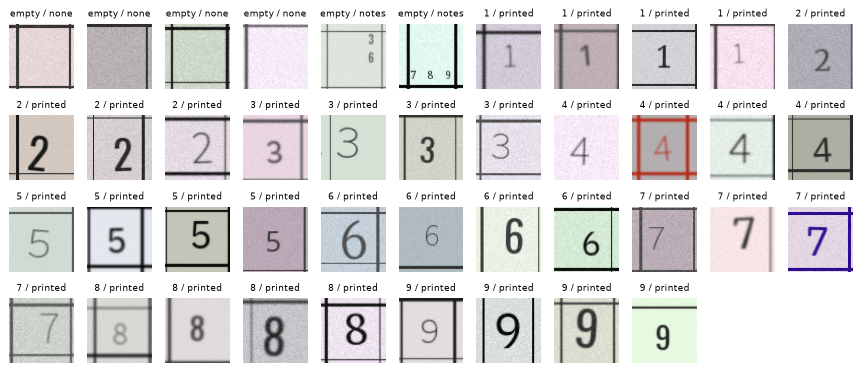

In [4]:
samples = synthetic.generate(per_class=4, seed=11, fonts=fonts)
samples = sorted(samples, key=lambda s: (s.digit, s.kind))
gallery(
    [s.image for s in samples],
    [f"{DIGIT_CLASSES[s.digit]} / {KIND_CLASSES[s.kind]}" for s in samples],
    columns=11,
)

## 4. Augmentation

Every training batch goes through `augment` before the preprocessing. Each cell gets its own
random distortion, on the GPU, with one `torch.Generator` for repeatable runs:

| Distortion | Range | Why |
| --- | --- | --- |
| Shift | ±4 px | The outline is a few pixels off |
| Rotate | ±6° | The page is not straight |
| Scale | ±10 % | Fonts and grids differ in size |
| Shear | ±0.1 | Perspective that the flatten did not remove |
| Blur | 40 % of cells | Focus and motion |
| Gamma, contrast, brightness | see `augment.py` | Light and paper colour |
| Noise | σ up to 6 | The camera sensor |

`affine_grid` works in coordinates from -1 to 1 over the 64 pixels, so 1 unit is 32 pixels.
That is why the shift is `uniform(-4, 4) / 32`. `padding_mode="border"` repeats the edge pixels,
as the flatten does.

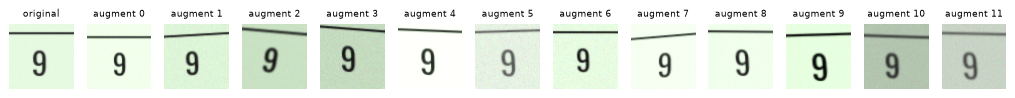

In [5]:
source = samples[-1].image  # a printed 9
batch = torch.from_numpy(np.stack([source] * 12)).permute(0, 3, 1, 2).float()
generator = torch.Generator().manual_seed(0)
out = augment(batch, generator).permute(0, 2, 3, 1).numpy().astype(np.uint8)
gallery([source] + list(out), ["original"] + [f"augment {i}" for i in range(12)], columns=13)

## 5. Groups and the split

A sudoku page often appears in the dataset more than once: two photos of the same page, or a
photo and a scan. The cells of one photo also share the font, the paper and the light. If a test
cell has siblings in the training set, the test measures memory, not skill.

So the split does not cut cells. It cuts **groups** (ADR-035):

1. `dhash` makes a 64-bit **difference hash** of each cell: an 8 × 9 gray thumbnail, then one bit
   per pixel that is brighter than its left neighbour. `group_ids` joins two cells with at most 4
   different bits (a union-find).
2. `group_ids` also joins every cell of one **page**. `read_real_cells` gives each cell with a
   source photo the **page key** of that photo. `page_keys` gives two photos one key when they
   share at least 10 digit cells at the same position, and 90 % of these hold the same digit.
3. `split_by_group` gives each group a side from a **hash** of the seed and the group key: 80 %
   to training, 10 % to validation and 10 % to the test set. The key of a group is its page key,
   or else the smallest file name of its cells.

The hash makes the split stable. A new cell never moves an old group to another side, so the
Check screen keeps its test cells after a fetch.

`split_cells` is the only entry point. Training and the Check screen of the labelling app both
call it, so they agree on which cells are test cells.

**Why the page rule.** 4 bits catch copies with almost the same pixels: a brighter copy, or the
same file saved again. A shift of 1 pixel or a little camera noise changes more than 4 bits. The
cells of one photo are never such copies. Before ADR-035, 55.6 % of the real test cells had a
sibling of the same photo in training. The next cell measures the hash, then shows the split.

In [6]:
rng = np.random.default_rng(1)
changes = {
    "brightness + 10": lambda a: a.astype(int) + 10,
    "noise, sigma 3": lambda a: a + rng.normal(0, 3, a.shape),
    "shift 1 px": lambda a: np.roll(a, 1, axis=1),
    "another cell": None,
}
digit_cells = [s for s in synthetic.generate(per_class=5, seed=14, fonts=fonts) if s.digit > 0]
for name, change in changes.items():
    bits = []
    for i, s in enumerate(digit_cells):
        b = (
            digit_cells[(i + 1) % len(digit_cells)].image
            if change is None
            else np.clip(change(s.image), 0, 255).astype(np.uint8)
        )
        bits.append(bin(dataset.dhash(s.image) ^ dataset.dhash(b)).count("1"))
    print(f"{name:>16}: median {np.median(bits):4.1f} different bits (one group at 4 or fewer)")

# A small set: 30 cells, each one twice (a near-copy), and 20 cells from 2 scan photos.
base = synthetic.generate(per_class=3, seed=12, fonts=fonts)[:30]
copies = [
    synthetic.Sample(np.clip(s.image.astype(int) + 2, 0, 255).astype(np.uint8), s.digit, s.kind)
    for s in base
]
scans = [
    synthetic.Sample(s.image, s.digit, s.kind, photo=f"photo-{i % 2}")
    for i, s in enumerate(synthetic.generate(per_class=2, seed=13, fonts=fonts)[:20])
]
demo = base + copies + scans
groups = dataset.group_ids(demo)
keys = [s.photo or f"cell-{i:03d}" for i, s in enumerate(demo)]
sides = dataset.split_by_group(groups, keys, (0.8, 0.1, 0.1), seed=7)
print(f"{len(demo)} cells in {len(set(groups))} groups")
for name, side in zip(("train", "val", "test"), sides, strict=True):
    print(f"{name:>5}: {len(side):3} cells in {len(set(groups[side].tolist()))} groups")
shared = set(groups[sides[0]]) & (set(groups[sides[1]]) | set(groups[sides[2]]))
print("groups on two sides:", shared or "none")

# 50 new cells: the sides of the old cells do not change.
more = demo + synthetic.generate(per_class=5, seed=15, fonts=fonts)[:50]
more_keys = keys + [f"new-{i:03d}" for i in range(50)]
more_sides = dataset.split_by_group(dataset.group_ids(more), more_keys, (0.8, 0.1, 0.1), seed=7)


def side_list(sides, n):
    side = {int(i): name for name, indices in zip("tvs", sides, strict=True) for i in indices}
    return [side[i] for i in range(n)]


moved = sum(
    a != b
    for a, b in zip(side_list(sides, len(demo)), side_list(more_sides, len(demo)), strict=True)
)
print(f"old cells on another side after 50 new cells: {moved}")

 brightness + 10: median  0.0 different bits (one group at 4 or fewer)
  noise, sigma 3: median  5.0 different bits (one group at 4 or fewer)
      shift 1 px: median  8.0 different bits (one group at 4 or fewer)
    another cell: median 28.0 different bits (one group at 4 or fewer)
80 cells in 32 groups
train:  68 cells in 26 groups
  val:   6 cells in 3 groups
 test:   6 cells in 3 groups
groups on two sides: none
old cells on another side after 50 new cells: 0


## 6. The model

`CellClassifier` (ADR-006) is a small convolutional network: about 73 000 weights, under 1 MB as
TFLite.

- Three blocks of two 3 × 3 convolutions, each with batch norm and ReLU. A max pool halves the
  size after the first two blocks: 32 → 16 → 8.
- **Global average pooling** turns the 64 feature maps into 64 numbers. The model then does not
  care where in the cell the digit sits.
- Two linear **heads** share these 64 numbers: `digit` (10 classes) and `kind` (4 classes).

The heads return **logits**, not probabilities. `ExportModel` adds the softmax and the
temperature for the app, and turns the input from NHWC (the app's layout) to NCHW (PyTorch's).

In [7]:
model = CellClassifier()
print(model)
print(f"\n{sum(p.numel() for p in model.parameters()):,} weights")
digit_logits, kind_logits = model(torch.zeros(81, 1, 32, 32))
print("digit logits", tuple(digit_logits.shape), "| kind logits", tuple(kind_logits.shape))

CellClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dila

## 7. The loss

`train.loss` adds two cross-entropy terms:

```text
loss = CE(digit, label_smoothing = 0.05) + kind_weight × CE(kind, only known kinds)
```

- **Label smoothing** moves 5 % of the target to the other classes. The model then does not push
  its logits to extremes, and its confidence stays more honest.
- **`kind_weight` = 0.4**: the digit is the main task.
- A cell with `UNKNOWN_KIND` adds no kind term. A batch without any known kind has the digit term
  only.

In [8]:
logits_d = torch.tensor([[0.1, 3.0] + [0.0] * 8, [2.0] + [0.0] * 9])
logits_k = torch.tensor([[0.0, 2.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0]])
digit_t = torch.tensor([1, 0])
for kind_t in (
    torch.tensor([kind_index("printed"), kind_index("none")]),
    torch.tensor([UNKNOWN_KIND, kind_index("none")]),
    torch.tensor([UNKNOWN_KIND, UNKNOWN_KIND]),
):
    value = train.loss(logits_d, logits_k, digit_t, kind_t, kind_weight=0.4, label_smoothing=0.05)
    print(f"kind targets {kind_t.tolist()}: loss {float(value):.4f}")

kind targets [1, 0]: loss 0.9144
kind targets [-1, 0]: loss 0.9949
kind targets [-1, -1]: loss 0.6975


## 8. A small training run

This is the loop of `train.fit`, written out so that the notebook can record the loss. It has
the same calls, made smaller:

- **Half synthetic, half real.** Each batch takes `batch_size / 2` random synthetic cells and
  `batch_size / 2` random real cells, with replacement. The share of real cells stays at 50 %,
  however many real cells exist. An "epoch" is `n_train / batch_size` such batches. This notebook
  has no real cells, so the batch is all synthetic, as in `configs/smoke.toml`.
- **AdamW** with weight decay, and a **one-cycle** learning rate: it rises to `max_lr`, then
  falls to almost zero.
- **The device** is the Apple GPU (`mps`) when it exists, else the CPU.

The real config (`configs/cell-classifier.toml`) trains 25 epochs on 2000 synthetic cells per
class and every trusted real cell.

epoch 1: loss 2.580


epoch 2: loss 1.746


epoch 3: loss 1.067


epoch 4: loss 0.848


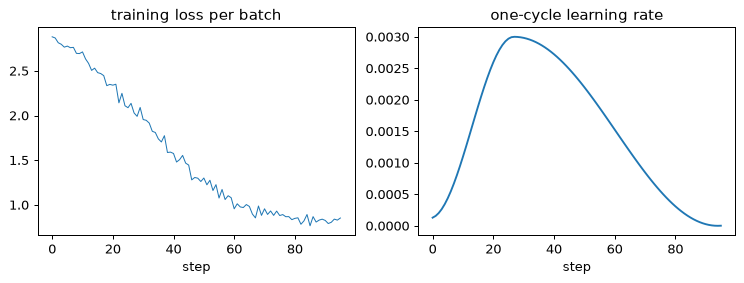

In [9]:
SEED, EPOCHS, BATCH, MAX_LR = 5, 4, 128, 0.003
torch.manual_seed(SEED)
generator = torch.Generator().manual_seed(SEED)
device = train.default_device()
train_set = synthetic.generate(per_class=300, seed=SEED, fonts=fonts)
val_set = synthetic.generate(per_class=40, seed=SEED + 1, fonts=fonts)
test_set = synthetic.generate(per_class=40, seed=SEED + 2, fonts=fonts)
images, digit_t, kind_t = dataset.stack(train_set)

net = CellClassifier().to(device)
steps = len(train_set) // BATCH
optimiser = torch.optim.AdamW(net.parameters(), lr=MAX_LR, weight_decay=1e-4)
schedule = torch.optim.lr_scheduler.OneCycleLR(optimiser, MAX_LR, total_steps=steps * EPOCHS)
history, rates = [], []
for epoch in range(EPOCHS):
    net.train()
    for _ in range(steps):
        pick = torch.randint(len(train_set), (BATCH,), generator=generator)
        x = images[pick].to(device).permute(0, 3, 1, 2).float()
        x = augment(x, generator)
        d, k = net(preprocess_batch(x))
        value = train.loss(d, k, digit_t[pick].to(device), kind_t[pick].to(device), 0.4, 0.05)
        optimiser.zero_grad()
        value.backward()
        optimiser.step()
        schedule.step()
        history.append(float(value))
        rates.append(schedule.get_last_lr()[0])
    print(f"epoch {epoch + 1}: loss {np.mean(history[-steps:]):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
a1.plot(history, lw=0.8)
a1.set_title("training loss per batch")
a1.set_xlabel("step")
a2.plot(rates)
a2.set_title("one-cycle learning rate")
a2.set_xlabel("step")
plt.show()

## 9. Accuracy and the confusion matrix

`train.predict_logits` runs the model in batches of 1024, without gradients and without augmentation.

digit accuracy 0.9762
kind accuracy  0.9524


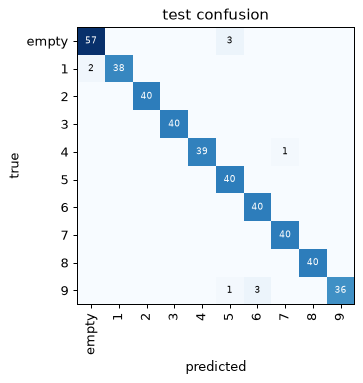

In [10]:
val_images, val_digit, _ = dataset.stack(val_set)
test_images, test_digit, test_kind = dataset.stack(test_set)
val_logits, _ = train.predict_logits(net, val_images, device)
test_logits, test_kind_logits = train.predict_logits(net, test_images, device)
prediction = test_logits.argmax(1)
print(f"digit accuracy {float((prediction == test_digit).float().mean()):.4f}")
print(f"kind accuracy  {float((test_kind_logits.argmax(1) == test_kind).float().mean()):.4f}")

confusion = np.zeros((10, 10), int)
for t, p in zip(test_digit.tolist(), prediction.tolist(), strict=True):
    confusion[t, p] += 1
plt.figure(figsize=(4.5, 4))
plt.imshow(confusion, cmap="Blues")
for t in range(10):
    for p in range(10):
        if confusion[t, p]:
            plt.text(
                p,
                t,
                confusion[t, p],
                ha="center",
                va="center",
                fontsize=7,
                color="white" if confusion[t, p] > confusion.max() / 2 else "black",
            )
plt.xticks(range(10), DIGIT_CLASSES, rotation=90)
plt.yticks(range(10), DIGIT_CLASSES)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("test confusion")
plt.show()

## 10. Calibration: is a 95 % answer right 95 % of the time?

The app trusts the model's confidence. It asks the player to check the cells under a threshold.
So the confidence must be **calibrated**: of all answers with 90 % confidence, about 90 % must be
right.

A trained network is often over-confident. **Temperature scaling** fixes this with one number
`T`: `softmax(logits / T)`. `T` > 1 makes the answers less sure, `T` < 1 makes them more sure.
The ranking of the classes does not change, so the accuracy stays the same.

- `fit_temperature` finds `T` on the **validation** set. It minimises the cross-entropy with
  LBFGS, over `log T`, so that `T` stays positive.
- The **expected calibration error** (ECE) groups the answers into 15 bins by confidence. It
  is the weighted mean gap between confidence and accuracy over the bins. 0 is perfect.
- The test set measures the result. It never takes part in a fit.

`ExportModel` applies `T` to the digit head only. The kind head has no fitted temperature.

Here `T` comes out below 1: the model is **under**-confident. Label smoothing (section 7) trains
the model to keep 5 % of its belief for the other classes, and a short run adds to that. The
real run of `configs/cell-classifier.toml` also has `T` below 1.

temperature 0.221
ECE before 0.3308, after 0.0195


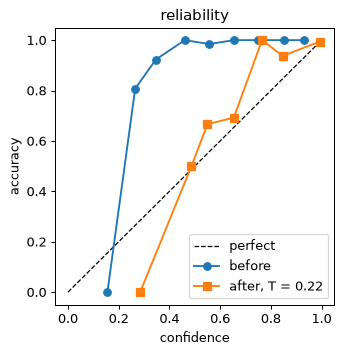

In [11]:
temperature = train.fit_temperature(val_logits, val_digit)
raw = test_logits.softmax(1)
scaled = (test_logits / temperature).softmax(1)
print(f"temperature {temperature:.3f}")
print(
    f"ECE before {train.expected_calibration_error(raw, test_digit):.4f}, "
    f"after {train.expected_calibration_error(scaled, test_digit):.4f}"
)


def reliability(probs, targets, bins=10):
    confidence, predicted = probs.max(1)
    correct = (predicted == targets).float()
    edges = torch.linspace(0, 1, bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:], strict=True):
        inside = (confidence > lo) & (confidence <= hi)
        if inside.any():
            xs.append(float(confidence[inside].mean()))
            ys.append(float(correct[inside].mean()))
    return xs, ys


plt.figure(figsize=(4, 4))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.plot(*reliability(raw, test_digit), "o-", label="before")
plt.plot(*reliability(scaled, test_digit), "s-", label=f"after, T = {temperature:.2f}")
plt.xlabel("confidence")
plt.ylabel("accuracy")
plt.legend()
plt.title("reliability")
plt.show()

## 11. Accuracy at a review rate

`review_accuracy` answers a product question: **if the player checks the least sure x % of the
cells, how accurate is the rest?** It sorts the answers by confidence, drops the lowest `x` %, and
measures the accuracy of the others. `metrics.json` holds it for 0 %, 1 %, 2 % and 5 %.

A grid has 81 cells, so a 2 % review rate is about 2 cells per scan.

In [12]:
print(train.review_accuracy(scaled, test_digit))

{'review_0%': 0.97619, 'review_1%': 0.980769, 'review_2%': 0.98301, 'review_5%': 0.992481}


## 12. What `just train` writes

A run is one folder in `ml/artifacts/<date>-<name>/`, outside git:

| File | Content |
| --- | --- |
| `model.pt` | The PyTorch weights |
| `metrics.json` | Accuracy, review rates, ECE, temperature, kind accuracy, counts, the config |
| `model-card.md` | The same in short prose, with the hash of `cells.csv` and the state of the kind labels |

A run with `real_cells = true` stays private (ADR-013). Set `SHOW_LOCAL_RUN = True` to see the
metrics of the newest run in `ml/artifacts/`. Clear the output before you commit.

In [13]:
runs = sorted(ARTIFACTS.glob("*/metrics.json"))
if not SHOW_LOCAL_RUN:
    print("SHOW_LOCAL_RUN is False: the metrics of local runs stay private.")
elif runs:
    latest = runs[-1].parent
    metrics = json.loads((latest / "metrics.json").read_text())
    print(latest.name)
    for key in (
        "eval_set",
        "digit_accuracy",
        "review",
        "ece",
        "temperature",
        "kind_accuracy_real",
        "n_train",
        "n_test",
        "device",
        "seconds",
    ):
        print(f"  {key:>20}: {metrics.get(key)}")
    print()
    print((latest / "model-card.md").read_text())
else:
    print("No runs in ml/artifacts/. Run `just train`.")

SHOW_LOCAL_RUN is False: the metrics of local runs stay private.


## 13. Export to TFLite

`just export <run>` converts the run with `litert-torch` and then refuses the result unless every
check passes (ADR-005):

1. **Operator versions.** Each operator must exist in TFLite 2.17, at a version that 2.17 runs
   (`tflite_2_17_ops.json`). The app's runtime is TFLite 2.17.
2. **float32 only.** No float16 or int8 weights. Shape constants in int32 or int64 are allowed.
3. **Size** under 1 MB.
4. **The same answers.** The 81 reference cells of `shared/fixtures/preprocess/` go through
   PyTorch and TFLite. The largest probability difference must be under 0.001. The digit and
   kind argmax must agree on every cell.

The export writes `export.json` (the checks) and `reference-outputs.json`. The app's tests compare
the phone's outputs with this file.

The next cell exports the small model of section 8 into a temporary folder.

In [14]:
fixtures = REPO_ROOT / "shared" / "fixtures" / "preprocess"
with tempfile.TemporaryDirectory() as tmp:
    run_dir = Path(tmp)
    torch.save(net.cpu().state_dict(), run_dir / "model.pt")
    (run_dir / "metrics.json").write_text(json.dumps({"temperature": temperature}))
    target = export(run_dir, fixtures)
    info = json.loads((run_dir / "export.json").read_text())
print(f"{info['bytes']:,} bytes, largest difference {info['max_abs_diff']:.2e}")
print("input", info["input_shape"], "| outputs", info["outputs"])
print("ops:", info["ops"])

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:00)

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:00)

...

(00:01) [ DONE] LiteRT-Torch Convert > Run LiteRT Converter Passes (+00:00)

(00:01) [ DONE] LiteRT-Torch Convert (+00:01)

(00:00) [START] Write Model to /var/folders/z2/b39x1dzs7dxf_r9kz06wp5nr0000gn/T/tmp2lq1e2hb/cell-classifier.tflite

(00:00) [ DONE] Write Model to /var/folders/z2/b39x1dzs7dxf_r9kz06wp5nr0000gn/T/tmp2lq1e2hb/cell-classifier.tflite 
(+00:00)

326,348 bytes, largest difference 4.65e-06
input [81, 32, 32, 1] | outputs {'digit': 0, 'kind': 1}
ops: {'DEPTHWISE_CONV_2D': 1, 'CONV_2D': 1, 'MAX_POOL_2D': 1, 'SUM': 1, 'MUL': 1, 'RESHAPE': 1, 'GATHER_ND': 1, 'FULLY_CONNECTED': 5, 'SOFTMAX': 1}


## 14. Into the app

`just install-model <run>` copies `cell-classifier.tflite` into `mobile/assets/models/` and writes
`manifest.json` with the name of the run. The app loads the file at start. In M0 no promote gate
checks the model first (ADR-007).

## Where to go next

- `ml/LABELLING.md`: how the labelling app makes the trusted labels of section 2.
- `docs/architecture/00-concepts/model-contract.md`: the input, the outputs and the classes.
- `ml/src/sudoku_ml/train.py`: the full `train()`, with real cells and the model card.